# Sequential observations

Use `posterior.append` to add measurements to an existing posterior while
reusing the work from conditioning. The GP parameters and measurement-error
variance stay fixed between updates.

In [1]:
import jax

jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp

from gpex import (
    FunctionalBlock,
    FunctionalDataset,
    FunctionalQuery,
    GaussianProcess,
    ObservationBlock,
    kernels,
    operators,
)
from gpex.blocks import Locations

## Reserve space for more observations

Start with the three measurements from [First posterior](first-posterior.ipynb).
Set `max_size=5` to reserve space for two more observations.

In [2]:
x_observed = jnp.array([[-1.4], [-1.0], [1.2]])
y_observed = jnp.array([-0.8, -0.5, 0.7])

dataset = FunctionalDataset([
    ObservationBlock.from_arrays(
        x_observed, y_observed,
        variance=0.02, name="observed_values", max_size=5,
    )
])

In [3]:
gp = GaussianProcess(
    kernels.RBFKernel(variance=1.0, lengthscale=0.5)
)
initial = gp.condition(dataset)

## Append observations

The `block` argument selects the observation block to extend. New observations
use that block's operator and measurement-error variance.

`append` returns a new posterior. The original posterior and `dataset` remain
unchanged.

In [4]:
x_first = jnp.array([[-0.3]])
y_first = jnp.array([0.9])
after_first = initial.append(
    Locations(x_first), y_first, block="observed_values"
)

Continue from the returned posterior to include another observation:

In [5]:
x_second = jnp.array([[0.4]])
y_second = jnp.array([-0.2])
after_second = after_first.append(
    Locations(x_second), y_second, block="observed_values"
)

## Compare the posteriors

In [6]:
x_plot = jnp.linspace(-2.0, 2.0, 101)[:, None]
query = FunctionalQuery([
    FunctionalBlock(x_plot, operators.Identity(), name="function")
])
predictions = [
    posterior.predict_marginals(query)
    for posterior in (initial, after_first, after_second)
]

In [7]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.18,
    "font.size": 10,
})


def plot_posterior(ax, prediction):
    mean = prediction.mean["function"]
    sd = jnp.sqrt(prediction.variance["function"])
    ax.fill_between(
        x_plot[:, 0], mean - 1.96 * sd, mean + 1.96 * sd,
        color="#1F4E79", alpha=0.15, linewidth=0,
        label="95% posterior interval",
    )
    ax.plot(x_plot[:, 0], mean, color="#1F4E79", label="Posterior mean")
    ax.scatter(
        x_observed[:, 0], y_observed, color="#D97706", marker="x",
        s=55, zorder=3, label="Initial measurements",
    )

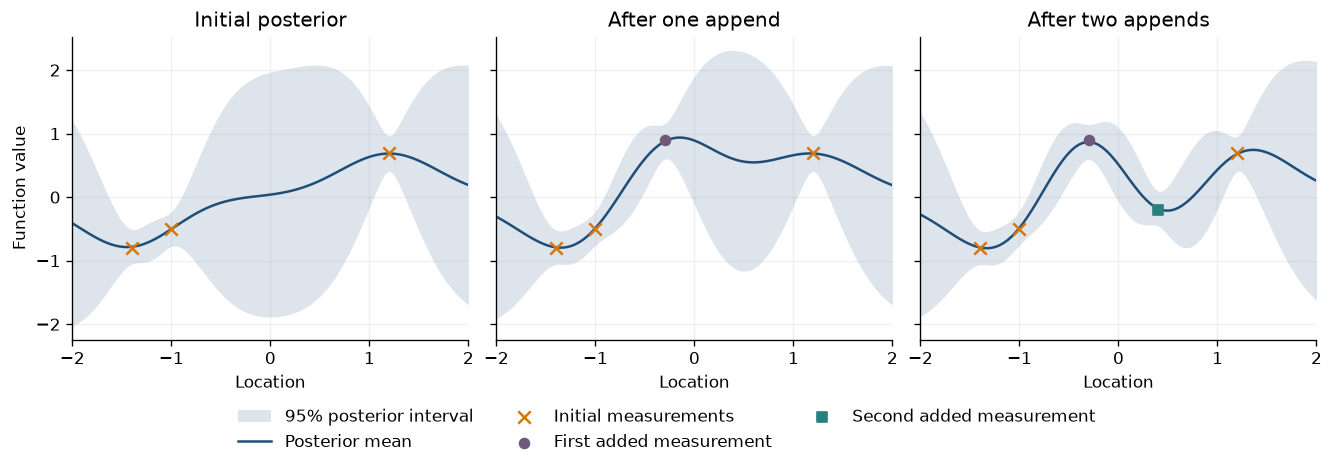

In [8]:
fig, axes = plt.subplots(
    1, 3, figsize=(11, 3.8), sharex=True, sharey=True, layout="constrained"
)
for ax, prediction, title in zip(
    axes, predictions, ("Initial posterior", "After one append", "After two appends")
):
    plot_posterior(ax, prediction)
    ax.set(title=title, xlabel="Location", xlim=(-2, 2))

for ax in axes[1:]:
    ax.scatter(
        x_first[:, 0], y_first, color="#6D597A", s=35, zorder=4,
        label="First added measurement",
    )
axes[2].scatter(
    x_second[:, 0], y_second, color="#2A7F7F", marker="s", s=35,
    zorder=4, label="Second added measurement",
)
axes[0].set_ylabel("Function value")
handles, labels = axes[2].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3, frameon=False)
plt.show()

All five reserved locations are now filled. Appending beyond `max_size`
raises an error, so reserve the planned total before conditioning.
See [JAX and observation capacity](../concepts/jax-and-capacity.md) for
compiling updates, changing capacity, or refitting the model.